In [3]:
# Let numpy stay at 2.x - just reinstall tiatoolbox cleanly
!pip install "numpy>=2.0" -q
!pip install tiatoolbox segmentation-models-pytorch openslide-python shapely geojson -q --upgrade

print("Done. Now go to Kernel → Restart Kernel before continuing.")

Done. Now go to Kernel → Restart Kernel before continuing.


In [1]:
import os
import json
import glob
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, random_split
from PIL import Image, ImageDraw
from shapely.geometry import shape, Polygon, MultiPolygon
import openslide
import segmentation_models_pytorch as smp
import geojson
from skimage import measure
import matplotlib.pyplot as plt
import traceback

print("Torch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())
print("OpenSlide version:", openslide.__version__)

Torch version: 2.12.0
GPU available: False
OpenSlide version: 1.4.3


In [2]:
BASE_DIR = "/Users/seymour/Downloads/Shomaiya/sa_segmentation/SN"

SLIDE_DIR   = BASE_DIR
GEOJSON_DIR = BASE_DIR
PATCH_DIR   = os.path.join(BASE_DIR, "Patch")
MODEL_DIR   = os.path.join(BASE_DIR, "Model")
PRED_DIR    = os.path.join(BASE_DIR, "Pred")

TRAINING_SLIDES = [
    "NPB139_LHE_B10",
    "NPB139_LHE_B17",
    "NPBB0.24_LHE_B21",
    "NPBB0.26_LHE_B21",
    "NPBB3_LHE_B10",
    "NPBB4_LHE_B19",
    "NPBB8_LHE_B11",
    "NPBB15_LHE_B11",
    "NPBB28_LHE_B10",
    "NPBB29_LHE_B11",
    "NPBB31_LHE_B10_DUPLICATE",
    "NPBB33_LHE_B10_DUPLICATE",
    "NPBB92_LHE_B10",
    "NPBB118_LHE_B10",
    "NPBB130_LHE_B10",
    "NPBB182_LHE_B2",
    "NPBB228_LHE_B3",
    "NPBB229_LHE_B2",
    "NPBB229_LHE_B3",
    "NPBB230_LHE_B2",
    "NPBB235_LHE_B2",
    "NPBB238_LHE_B2",
    "NPBB246_LHE_B2",
    "NPBB280_LHE_B2",
    "NPBB318_LHE_B2",
    "NPBB319_LHE_B3",
    "NPBB324_LHE_B2",
    "NPBB325_LHE_B3",
    "NPBB359_LHE_B3",
    "NPBB383_B3_LHE (3)",
    "NPBB390_LHE_B3",
    "NPBB393_LHE_B2",
    "NPBB393_LHE_B3",
    "NPBB400_LHE_B3",
    "NPBB409_LHE_B2",
    "NPBB412_LHE_B2",
    "NPBB415_LHE_B2",
    "NPBB439_LHE_B2",
    "NPBB2_LHE_B21",
    "NPBB2_LHE_B25",
    "NPBB194_4G8_B11",
    "NPBB194_4G8_B14",
    "NPBB198_LHE_B3",
    "NPBB203_LHE_B2",
    "NPBB203_LHE_B3",
    "NPBB454_LHE_B2",
    "NPBB227_LHE_A33",
    "NPBB227_LHE_A3",
    "NPBB227_LHE_A2",
    "NPBB221_LHE_B3",
    "NPBB218_LHE_A3",
    "NPBB216_LHE_B63",
    "NPBB215_LHE_B63",
    "NPBB215_LHE_B62",
    "NPBB51_LHE_A10",
    "NPBB6_LHE_A11",
    "NPB137_HE_B10",
    "NPB139_HE_B10_RECUT",
    "NPB139_HE_B17_RECUT",
    "NPBB0.13_HE_B7",
    "NPBB0.16_HE_B13_NA",
    "NPBB0.18_HE_B10",
    "NPBB1_HE_B13",
    "NPBB8_HE_B11",
    "NPBB9_HE_B11",
    "NPBB12_HE_B11",
    "NPBB13_HE_B11",
    "NPBB24_HE_B11",
    "NPBB28_HE_B10",
    "NPBB30_HE_B10",
    "NPBB33_HE_B10",
    "NPBB34_HE_B10",
    "NPBB36_HE_B10",
    "NPBB37_HE_A10",
    "NPBB40_HE_B10_Duplicate",
    "NPBB49_LAM_HE_B10",
    "NPBB53_HE_B10",
    "NPBB58_HE_B10",
    "NPBB58_HE_B26",
    "NPBB81_HE_B10",
    "NPBB83_HE_B10",
    "NPBB92_HE_B10",
    "NPBB127_HE_B10",
    "NPBB130_HE_B10",
    "NPBB134_HE_B10",
    "NPBB202_HE_B2",
    "NPBB204_HE_B3",
    "NPBB233_HE_B3_Duplicate",
    "NPBB240_HE_B3_Duplicate",
    "NPBB319_HE_B3",
    "NPBB388_HE_B2",
    "NPBB21_HE_B11",
    "NPBB201_HE_B3",
    "NPBB203_HE_B2",
    "NPBB227_HE_A33",
    "NPBB227_HE_A2",
    "NPBB221_HE_B2",
    "NPBB220_HE_B1",
    "NPBB218_HE_A3",
    "NPBB47_HE_B10",
    "NPBB22_HE_B11",
    "MA18-77_HE_B25",
]
# Add this to Cell 3
REFERENCE_SLIDE = os.path.join(SLIDE_DIR, "NPBB8_LHE_B11.svs")
# Change to whichever of your 6 SVS slides has the clearest staining
# Lower resolution = smaller image = fewer patches
# Higher level number = lower resolution
# We use level 2 in geojson_to_mask — this controls patch count
RESOLUTION = 1.25
PATCH_SIZE  = 256  # reduced from 512 — gives 4x more patches

for d in [PATCH_DIR, MODEL_DIR, PRED_DIR]:
    os.makedirs(d, exist_ok=True)

# ── Verify files exist ───────────────────────────────────
print("Checking files...\n")

for name in TRAINING_SLIDES:
    slide_path = os.path.join(SLIDE_DIR, name + ".svs")

    # This allows filenames like:
    # NPBB8_LHE_B11_SA_Jan_2026.geojson
    geojson_matches = glob.glob(os.path.join(GEOJSON_DIR, name + "*.geojson"))

    print(name)
    print("  SVS:    ", "OK" if os.path.exists(slide_path) else "MISSING")
    print("  GeoJSON:", "OK" if geojson_matches else "MISSING")

    if geojson_matches:
        print("  using:  ", os.path.basename(geojson_matches[0]))

    print()

print("Folders ready")

print("Folders ready")

Checking files...

NPB139_LHE_B10
  SVS:     OK
  GeoJSON: OK
  using:   NPB139_LHE_B10_SA_Feb_2026.geojson

NPB139_LHE_B17
  SVS:     OK
  GeoJSON: OK
  using:   NPB139_LHE_B17_SA_Feb_2026.geojson

NPBB0.24_LHE_B21
  SVS:     OK
  GeoJSON: OK
  using:   NPBB0.24_LHE_B21_DUPLICATE_SA_Jan_2026.geojson

NPBB0.26_LHE_B21
  SVS:     OK
  GeoJSON: OK
  using:   NPBB0.26_LHE_B21_SA_Jan_2026.geojson

NPBB3_LHE_B10
  SVS:     OK
  GeoJSON: OK
  using:   NPBB3_LHE_B10_SA_Feb_2026.geojson

NPBB4_LHE_B19
  SVS:     OK
  GeoJSON: OK
  using:   NPBB4_LHE_B19_SA_Feb_2026.geojson

NPBB8_LHE_B11
  SVS:     OK
  GeoJSON: OK
  using:   NPBB8_LHE_B11_SA_Jan_2026.geojson

NPBB15_LHE_B11
  SVS:     OK
  GeoJSON: OK
  using:   NPBB15_LHE_B11_SA_Feb_2026.geojson

NPBB28_LHE_B10
  SVS:     OK
  GeoJSON: OK
  using:   NPBB28_LHE_B10_SA_Feb_2026.geojson

NPBB29_LHE_B11
  SVS:     OK
  GeoJSON: OK
  using:   NPBB29_LHE_B11_SA_Feb_2026.geojson

NPBB31_LHE_B10_DUPLICATE
  SVS:     OK
  GeoJSON: OK
  using:   NPBB3

In [3]:
import openslide
from shapely.geometry import shape, Polygon, MultiPolygon
import json
import numpy as np
from PIL import Image, ImageDraw

def get_best_level(oslide, target_mpp=8.0):
    """
    Pick pyramid level closest to target_mpp microns per pixel.
    SVS files always have MPP metadata so no fallback needed.
    target_mpp=8.0 gives ~5000px thumbnail for a 40x SVS scan.
    """
    base_mpp_x = float(
        oslide.properties.get(openslide.PROPERTY_NAME_MPP_X, 0.25)
    )

    best_level = 0
    best_diff  = float('inf')
    for lvl in range(oslide.level_count):
        downsample = oslide.level_downsamples[lvl]
        level_mpp  = base_mpp_x * downsample
        diff       = abs(level_mpp - target_mpp)
        print(f"    Level {lvl}: {oslide.level_dimensions[lvl]}, "
              f"MPP={level_mpp:.2f}")
        if diff < best_diff:
            best_diff  = diff
            best_level = lvl

    print(f"    → Chose level {best_level} "
          f"(MPP≈{base_mpp_x * oslide.level_downsamples[best_level]:.2f})")
    return best_level


def geojson_to_mask(geojson_path, slide_path):
    oslide         = openslide.OpenSlide(slide_path)
    base_w, base_h = oslide.dimensions

    chosen_level = get_best_level(oslide, target_mpp=8.0)
    dims         = oslide.level_dimensions[chosen_level]
    region       = oslide.read_region((0, 0), chosen_level, dims)
    thumb        = np.array(region.convert("RGB"))
    oslide.close()

    thumb_h, thumb_w = thumb.shape[:2]
    scale_x = thumb_w / base_w
    scale_y = thumb_h / base_h

    print(f"  Base dims:     {base_w} x {base_h}")
    print(f"  Thumbnail:     {thumb_w} x {thumb_h}")
    print(f"  Scale factors: {scale_x:.6f}, {scale_y:.6f}")

    with open(geojson_path) as f:
        gj = json.load(f)

    mask     = Image.new("L", (thumb_w, thumb_h), 0)
    draw     = ImageDraw.Draw(mask)
    features = gj.get("features", [])
    print(f"  Features in GeoJSON: {len(features)}")

    sn_found = 0
    for i, feature in enumerate(features):
        props = feature.get("properties", {})
        if "classification" in props:
            cls  = props.get("classification", {})
            name = cls.get("name", "") if isinstance(cls, dict) else str(cls)
        else:
            name = props.get("name", "")

        print(f"  Feature {i}: name='{name}', "
              f"type='{feature['geometry']['type']}'")

        geom = shape(feature["geometry"])

        if geom.geom_type == "LineString":
            coords = list(geom.coords)
            if coords[0] != coords[-1]:
                coords.append(coords[0])
            geom = Polygon(coords)
            print(f"    Converted LineString → Polygon, "
                  f"valid: {geom.is_valid}")

        if geom.geom_type == "Polygon":
            polys = [geom]
        elif geom.geom_type == "MultiPolygon":
            polys = list(geom.geoms)
        else:
            print(f"    Skipping: {geom.geom_type}")
            continue

        for poly in polys:
            scaled = [(x * scale_x, y * scale_y)
                      for x, y in poly.exterior.coords]
            draw.polygon(scaled, fill=255)
            sn_found += 1

    mask_arr = np.array(mask)
    print(f"  SN annotations drawn: {sn_found}")
    print(f"  SN pixels: {(mask_arr > 128).sum():,} / "
          f"{mask_arr.size:,} total")

    return np.array(thumb), mask_arr

print("Cell 4 defined ✓")

Cell 4 defined ✓


In [4]:
import glob
import os
import gc
import psutil
import cv2

def print_ram():
    ram = psutil.virtual_memory()
    print(f"  RAM: {ram.used/1e9:.1f}/{ram.total/1e9:.1f}GB "
          f"({ram.percent:.0f}%)")


def reinhard_normalize(source, target):
    """
    Reinhard normalization in LAB color space.
    Matches overall color tone/contrast to reference slide.
    Safe for LHE — preserves neuromelanin brown pigment signal.
    """
    source_lab = cv2.cvtColor(
        source.astype(np.uint8), cv2.COLOR_RGB2LAB
    ).astype(np.float32)
    target_lab = cv2.cvtColor(
        target.astype(np.uint8), cv2.COLOR_RGB2LAB
    ).astype(np.float32)

    result = np.zeros_like(source_lab)
    for ch in range(3):
        src_mean = source_lab[:,:,ch].mean()
        src_std  = source_lab[:,:,ch].std()
        tgt_mean = target_lab[:,:,ch].mean()
        tgt_std  = target_lab[:,:,ch].std()
        if src_std < 1e-6:
            result[:,:,ch] = source_lab[:,:,ch]
            continue
        result[:,:,ch] = (
            (source_lab[:,:,ch] - src_mean) *
            (tgt_std / src_std) + tgt_mean
        )

    result = np.clip(result, 0, 255).astype(np.uint8)
    result = cv2.cvtColor(result, cv2.COLOR_LAB2RGB)
    return result


def extract_patches(image, mask, patch_size=256, stride=128):
    sn_imgs, sn_masks = [], []
    bg_imgs, bg_masks = [], []
    h, w = mask.shape
    total = ((h-patch_size)//stride) * ((w-patch_size)//stride)
    print(f"  Image: {w}x{h}, patch: {patch_size}, stride: {stride}")
    print(f"  Max possible patches: {total}")

    for y in range(0, h - patch_size, stride):
        for x in range(0, w - patch_size, stride):
            img_p  = image[y:y+patch_size, x:x+patch_size]
            mask_p = mask[y:y+patch_size,  x:x+patch_size]
            if img_p.mean() > 240:
                continue
            sn_frac = (mask_p > 128).sum() / (patch_size ** 2)
            if sn_frac >= 0.05:
                sn_imgs.append(img_p)
                sn_masks.append(mask_p)
            elif sn_frac < 0.01:
                bg_imgs.append(img_p)
                bg_masks.append(mask_p)

    print(f"  SN patches:  {len(sn_imgs)}")
    print(f"  BG patches:  {len(bg_imgs)}")

    if len(sn_imgs) == 0:
        print("  WARNING: no SN patches found")
        return [], []

    n      = min(len(sn_imgs), len(bg_imgs))
    bg_idx = np.random.choice(len(bg_imgs), n, replace=False)
    all_imgs  = sn_imgs + [bg_imgs[i] for i in bg_idx]
    all_masks = sn_masks + [bg_masks[i] for i in bg_idx]
    print(f"  Balanced total: {len(all_imgs)} ({n} SN + {n} BG)")
    return all_imgs, all_masks


# ---------------------------------------------------------------
# Load reference slide for Reinhard normalization
# Change REFERENCE_SLIDE in Cell 3 if you want a different reference
# ---------------------------------------------------------------
print("Loading reference slide thumbnail...")
ref_oslide   = openslide.OpenSlide(REFERENCE_SLIDE)
ref_level    = get_best_level(ref_oslide, target_mpp=8.0)
ref_dims     = ref_oslide.level_dimensions[ref_level]
ref_region   = ref_oslide.read_region((0, 0), ref_level, ref_dims)
ref_thumb    = np.array(ref_region.convert("RGB"))
ref_oslide.close()
print(f"Reference thumbnail: {ref_thumb.shape} ✓")


# ---------------------------------------------------------------
# Patch extraction loop — SVS only
# ---------------------------------------------------------------
all_images, all_masks = [], []

for name in TRAINING_SLIDES:
    slide_path   = os.path.join(SLIDE_DIR, name + ".svs")
    geojson_path = glob.glob(
        os.path.join(GEOJSON_DIR, name + "*.geojson")
    )

    if not os.path.exists(slide_path):
        print(f"WARNING: slide not found — {slide_path}")
        continue
    if len(geojson_path) == 0:
        print(f"WARNING: geojson not found for {name}")
        continue
    geojson_path = geojson_path[0]

    print(f"\nProcessing {name}...")
    print_ram()

    try:
        img, mask = geojson_to_mask(geojson_path, slide_path)

        if (mask > 128).sum() == 0:
            print("  Skipping — empty mask")
            del img, mask
            gc.collect()
            continue

        # Normalize all slides to reference
        # Skip normalization for the reference slide itself
        if os.path.basename(slide_path) != \
           os.path.basename(REFERENCE_SLIDE):
            print("  Normalizing stain (Reinhard)...")
            img_norm = reinhard_normalize(img, ref_thumb)
        else:
            print("  Reference slide — skipping normalization")
            img_norm = img.copy()

        del img
        gc.collect()

        imgs, masks = extract_patches(
            img_norm, mask,
            patch_size=PATCH_SIZE,
            stride=128
        )
        del img_norm, mask
        gc.collect()

        if len(imgs) == 0:
            print("  Skipping — no patches extracted")
            continue

        all_images.extend(imgs)
        all_masks.extend(masks)
        del imgs, masks
        gc.collect()

        print(f"  Running total: {len(all_images)} patches")
        print_ram()

    except Exception as e:
        import traceback
        print(f"  ERROR: {e}")
        traceback.print_exc()
        gc.collect()
        continue

print(f"\nFinal total: {len(all_images)} patches")

if len(all_images) > 0:
    np.save(os.path.join(PATCH_DIR, "images.npy"),
            np.array(all_images, dtype=np.uint8))
    del all_images
    gc.collect()
    np.save(os.path.join(PATCH_DIR, "masks.npy"),
            np.array(all_masks, dtype=np.uint8))
    del all_masks
    gc.collect()
    print(f"Saved to {PATCH_DIR}")
else:
    print("Nothing saved — check errors above")

Loading reference slide thumbnail...
    Level 0: (105156, 86265), MPP=0.26
    Level 1: (26289, 21566), MPP=1.05
    Level 2: (6572, 5391), MPP=4.20
    Level 3: (1643, 1347), MPP=16.81
    → Chose level 2 (MPP≈4.20)
Reference thumbnail: (5391, 6572, 3) ✓

Processing NPB139_LHE_B10...
  RAM: 90.1/549.8GB (17%)
    Level 0: (144746, 73604), MPP=0.26
    Level 1: (36186, 18401), MPP=1.05
    Level 2: (9046, 4600), MPP=4.20
    Level 3: (2261, 1150), MPP=16.81
    → Chose level 2 (MPP≈4.20)
  Base dims:     144746 x 73604
  Thumbnail:     9046 x 4600
  Scale factors: 0.062496, 0.062497
  Features in GeoJSON: 1
  Feature 0: name='Substantia Nigra', type='LineString'
    Converted LineString → Polygon, valid: True
  SN annotations drawn: 1
  SN pixels: 1,723,712 / 41,611,600 total
  Normalizing stain (Reinhard)...
  Image: 9046x4600, patch: 256, stride: 128
  Max possible patches: 2244
  SN patches:  153
  BG patches:  782
  Balanced total: 306 (153 SN + 153 BG)
  Running total: 306 patche

In [5]:
# ==========================
# Train U-Net for SN segmentation
# MPS-safe version for Mac
# ==========================

import os
import numpy as np
import torch
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, random_split
import segmentation_models_pytorch as smp


# ==========================
# Dataset
# ==========================

class SNDataset(Dataset):
    def __init__(self, images_path, masks_path):
        self.images = np.load(images_path, mmap_mode="r")
        self.masks = np.load(masks_path, mmap_mode="r")

        print(f"Dataset contains {len(self.images)} patches")

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        img = self.images[idx].copy().astype(np.float32) / 255.0
        mask = self.masks[idx].copy().astype(np.float32) / 255.0

        img = torch.tensor(img).permute(2, 0, 1)
        mask = torch.tensor(mask).unsqueeze(0)

        return img, mask


# ==========================
# Metrics
# ==========================

def compute_metrics(logits, masks, threshold=0.5):
    probs = torch.sigmoid(logits)
    preds = (probs > threshold).float()
    masks = (masks > 0.5).float()

    tp = (preds * masks).sum()
    fp = (preds * (1 - masks)).sum()
    fn = ((1 - preds) * masks).sum()
    tn = ((1 - preds) * (1 - masks)).sum()

    eps = 1e-8

    dice = (2 * tp) / (2 * tp + fp + fn + eps)
    iou = tp / (tp + fp + fn + eps)
    pixel_acc = (tp + tn) / (tp + tn + fp + fn + eps)
    precision = tp / (tp + fp + eps)
    recall = tp / (tp + fn + eps)

    return {
        "dice": dice.item(),
        "iou": iou.item(),
        "pixel_acc": pixel_acc.item(),
        "precision": precision.item(),
        "recall": recall.item(),
    }


# ==========================
# Load dataset
# ==========================

dataset = SNDataset(
    os.path.join(PATCH_DIR, "images.npy"),
    os.path.join(PATCH_DIR, "masks.npy")
)

n_val = max(2, int(len(dataset) * 0.20))
n_train = len(dataset) - n_val

train_set, val_set = random_split(
    dataset,
    [n_train, n_val],
    generator=torch.Generator().manual_seed(42)
)

print(f"Train patches: {n_train}")
print(f"Val patches:   {n_val}")


# ==========================
# MPS-safe DataLoaders
# ==========================

train_loader = DataLoader(
    train_set,
    batch_size=4,
    shuffle=True,
    num_workers=0,
    pin_memory=False
)

val_loader = DataLoader(
    val_set,
    batch_size=4,
    shuffle=False,
    num_workers=0,
    pin_memory=False
)


# ==========================
# Device
# ==========================

if torch.backends.mps.is_available():
    device = torch.device("mps")
elif torch.cuda.is_available():
    device = torch.device("cuda")
else:
    device = torch.device("cpu")

print("Using device:", device)
print("MPS available:", torch.backends.mps.is_available())
print("CUDA available:", torch.cuda.is_available())


# ==========================
# Model
# ==========================

model = smp.Unet(
    encoder_name="resnet50",
    encoder_weights="imagenet",
    in_channels=3,
    classes=1
).to(device)


# ==========================
# Loss, optimizer, scheduler
# ==========================

dice_loss = smp.losses.DiceLoss(mode="binary")
bce_loss = torch.nn.BCEWithLogitsLoss()

def criterion(logits, masks):
    return dice_loss(logits, masks) + 0.5 * bce_loss(logits, masks)

optimizer = optim.Adam(model.parameters(), lr=1e-4)

scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=4
)


# ==========================
# Training settings
# ==========================

EPOCHS = 100
PATIENCE = 12
MIN_DELTA = 0.001

best_dice = 0.0
epochs_without_improvement = 0

history = {
    "train_loss": [],
    "val_loss": [],
    "val_dice": [],
    "val_iou": [],
    "val_pixel_acc": [],
    "val_precision": [],
    "val_recall": [],
}

os.makedirs(MODEL_DIR, exist_ok=True)


# ==========================
# Training loop
# ==========================

for epoch in range(EPOCHS):
    model.train()
    train_loss = 0.0

    for imgs, masks in train_loader:
        imgs = imgs.to(device)
        masks = masks.to(device)

        optimizer.zero_grad()
        logits = model(imgs)
        loss = criterion(logits, masks)
        loss.backward()
        optimizer.step()

        train_loss += loss.item()

    avg_train_loss = train_loss / len(train_loader)

    model.eval()
    val_loss = 0.0

    metric_sums = {
        "dice": 0.0,
        "iou": 0.0,
        "pixel_acc": 0.0,
        "precision": 0.0,
        "recall": 0.0,
    }

    with torch.no_grad():
        for imgs, masks in val_loader:
            imgs = imgs.to(device)
            masks = masks.to(device)

            logits = model(imgs)
            loss = criterion(logits, masks)
            val_loss += loss.item()

            batch_metrics = compute_metrics(logits, masks)

            for key in metric_sums:
                metric_sums[key] += batch_metrics[key]

    avg_val_loss = val_loss / len(val_loader)

    avg_metrics = {
        key: value / len(val_loader)
        for key, value in metric_sums.items()
    }

    avg_dice = avg_metrics["dice"]
    scheduler.step(avg_dice)

    history["train_loss"].append(avg_train_loss)
    history["val_loss"].append(avg_val_loss)
    history["val_dice"].append(avg_metrics["dice"])
    history["val_iou"].append(avg_metrics["iou"])
    history["val_pixel_acc"].append(avg_metrics["pixel_acc"])
    history["val_precision"].append(avg_metrics["precision"])
    history["val_recall"].append(avg_metrics["recall"])

    improved = avg_dice > best_dice + MIN_DELTA

    if improved:
        best_dice = avg_dice
        epochs_without_improvement = 0

        torch.save(
            model.state_dict(),
            os.path.join(MODEL_DIR, "sn_unet_best.pth")
        )

        status = "BEST SAVED"

    else:
        epochs_without_improvement += 1
        status = f"No improvement: {epochs_without_improvement}/{PATIENCE}"

    if (epoch + 1) % 5 == 0:
        print(
            f"Epoch {epoch+1:3d}/{EPOCHS} | "
            f"Train Loss: {avg_train_loss:.4f} | "
            f"Val Loss: {avg_val_loss:.4f} | "
            f"Dice: {avg_metrics['dice']:.4f} | "
            f"IoU: {avg_metrics['iou']:.4f} | "
            f"Acc: {avg_metrics['pixel_acc']:.4f} | "
            f"Precision: {avg_metrics['precision']:.4f} | "
            f"Recall: {avg_metrics['recall']:.4f}"
        )

    if (epoch + 1) % 5 == 0:
        torch.save(
            model.state_dict(),
            os.path.join(MODEL_DIR, f"sn_unet_epoch{epoch+1}.pth")
        )

    if epochs_without_improvement >= PATIENCE:
        print(
            f"\nEarly stopping triggered at epoch {epoch+1}. "
            f"Best validation Dice: {best_dice:.4f}"
        )
        break

    if torch.cuda.is_available():
        torch.cuda.empty_cache()


print("\nTraining complete.")
print(f"Best validation Dice: {best_dice:.4f}")
print("Best model saved to:", os.path.join(MODEL_DIR, "sn_unet_best.pth"))

Dataset contains 36996 patches
Train patches: 29597
Val patches:   7399
Using device: mps
MPS available: True
CUDA available: False
Epoch   5/100 | Train Loss: 0.3330 | Val Loss: 0.3517 | Dice: 0.7583 | IoU: 0.6863 | Acc: 0.9147 | Precision: 0.7850 | Recall: 0.7693
Epoch  10/100 | Train Loss: 0.1969 | Val Loss: 0.2326 | Dice: 0.8091 | IoU: 0.7482 | Acc: 0.9408 | Precision: 0.8077 | Recall: 0.8339
Epoch  15/100 | Train Loss: 0.1352 | Val Loss: 0.2453 | Dice: 0.8048 | IoU: 0.7394 | Acc: 0.9296 | Precision: 0.7822 | Recall: 0.8585
Epoch  20/100 | Train Loss: 0.1020 | Val Loss: 0.1807 | Dice: 0.8402 | IoU: 0.7893 | Acc: 0.9586 | Precision: 0.8517 | Recall: 0.8437
Epoch  25/100 | Train Loss: 0.0832 | Val Loss: 0.1726 | Dice: 0.8434 | IoU: 0.7920 | Acc: 0.9576 | Precision: 0.8447 | Recall: 0.8554
Epoch  30/100 | Train Loss: 0.0651 | Val Loss: 0.1875 | Dice: 0.8423 | IoU: 0.7868 | Acc: 0.9529 | Precision: 0.8617 | Recall: 0.8405
Epoch  35/100 | Train Loss: 0.0340 | Val Loss: 0.1161 | Dice: 0.

In [5]:
import cv2
from scipy import ndimage
from skimage.morphology import dilation, erosion, disk
from skimage.measure import label, regionprops, approximate_polygon, find_contours

def postprocess_prediction(prob_map, threshold=0.4,
                            dilation_radius=8, min_region_size=500):
    binary  = (prob_map > threshold).astype(np.uint8)
    print(f"  After threshold:   {binary.sum():,} pixels")
    dilated = dilation(binary, disk(dilation_radius)).astype(np.uint8)
    print(f"  After dilation:    {dilated.sum():,} pixels")
    filled  = ndimage.binary_fill_holes(dilated).astype(np.uint8)
    eroded  = erosion(filled, disk(max(1, dilation_radius-2))).astype(np.uint8)
    print(f"  After erosion:     {eroded.sum():,} pixels")
    labeled = label(eroded)
    props   = regionprops(labeled)
    clean   = np.zeros_like(eroded)
    kept    = 0
    for prop in props:
        if prop.area >= min_region_size:
            clean[labeled == prop.label] = 1
            kept += 1
    print(f"  Regions kept:      {kept}")
    return clean


def mask_to_geojson(clean_mask, scale_x, scale_y):
    contours = find_contours(clean_mask.astype(float), 0.5)
    features = []
    for contour in contours:
        if len(contour) < 20:
            continue
        contour = approximate_polygon(contour, tolerance=2)
        coords  = [[float(c[1] * scale_x), float(c[0] * scale_y)]
                   for c in contour]
        coords.append(coords[0])
        features.append({
            "type": "Feature",
            "geometry": {"type": "Polygon", "coordinates": [coords]},
            "properties": {"classification": {"name": "Substantia Nigra"}}
        })
    return {"type": "FeatureCollection", "features": features}


def predict_on_slide(slide_path, model, threshold=0.5):
    oslide         = openslide.OpenSlide(slide_path)
    base_w, base_h = oslide.dimensions
    chosen_level   = 0
    for lvl in range(oslide.level_count):
        w, h = oslide.level_dimensions[lvl]
        if w >= 2000:
            chosen_level = lvl
    dims   = oslide.level_dimensions[chosen_level]
    region = oslide.read_region((0, 0), chosen_level, dims)
    thumb  = np.array(region.convert("RGB"))
    oslide.close()

    # Apply Reinhard normalization
    thumb = reinhard_normalize(thumb, ref_thumb)

    thumb_h, thumb_w = thumb.shape[:2]
    scale_x = base_w / thumb_w
    scale_y = base_h / thumb_h
    print(f"  Thumbnail: {thumb_w} x {thumb_h}")

    patch_size = 256
    stride     = 128
    prob_map   = np.zeros((thumb_h, thumb_w), dtype=np.float32)
    count_map  = np.zeros((thumb_h, thumb_w), dtype=np.float32)

    model.eval()
    torch.cuda.empty_cache()

    with torch.no_grad():
        for y in range(0, thumb_h - patch_size, stride):
            for x in range(0, thumb_w - patch_size, stride):
                patch = thumb[y:y+patch_size, x:x+patch_size]
                if patch.mean() > 240:
                    continue
                img_t = torch.tensor(
                    patch.astype(np.float32) / 255.0
                ).permute(2, 0, 1).unsqueeze(0).to(device)
                pred = torch.sigmoid(model(img_t)).squeeze().cpu().numpy()
                prob_map[y:y+patch_size, x:x+patch_size]  += pred
                count_map[y:y+patch_size, x:x+patch_size] += 1

    count_map[count_map == 0] = 1
    prob_map = prob_map / count_map
    print("  Prediction complete")
    return prob_map, thumb

print("Functions defined ✓")


Functions defined ✓


In [7]:
# Run Cell 2 (imports)
# Run Cell 3 (paths)
# Run Cell 4 (geojson_to_mask + get_best_level)
# Run Cell 5 only up to ref_thumb loading — skip patch extraction loop

# Then load model:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = smp.Unet(
    encoder_name="resnet50",
    encoder_weights=None,
    in_channels=3,
    classes=1,
).to(device)

# Load the trained model from the local MODEL_DIR
MODEL_PATH = os.path.join(MODEL_DIR, "sn_unet_best.pth")

model.load_state_dict(
    torch.load(MODEL_PATH, map_location=device)
)

model.eval()

print(f"Model loaded ✓")
print(f"Model path: {MODEL_PATH}")
print(f"Device: {device}")

# Then add new slide names to unannotated list and run Cell 8

Model loaded ✓
Model path: /Users/seymour/Downloads/Shomaiya/sa_segmentation/SN/Model/sn_unet_best.pth
Device: cpu


Unannotated slides: 11
  NPBB399_LHE_B2.svs
  NPBB13_LHE_B11.svs
  NPBB15_HE_B11.svs
  NPBB390_LHE_B2.svs
  NPBB25_LHE_B11.svs
  NPBB398_LHE_B3.svs
  NPPBB29_HE_B11.svs
  NPBB14_HE_B11.svs
  NPBB23_HE_B11.svs
  NPB137_LHE_B10.svs
  NPBB202_LHE_B3.svs

Predicting: NPBB399_LHE_B2
  Thumbnail: 6182 x 5504
  Prediction complete
  After threshold:   2,520,174 pixels
  After dilation:    2,952,864 pixels
  After erosion:     2,741,913 pixels
  Regions kept:      54
  Clusters found: 36 | kept: 1 | removed: 35
  Saved: NPBB399_LHE_B2_thresh0.3_dil8.geojson
  After threshold:   2,338,279 pixels
  After dilation:    2,823,930 pixels
  After erosion:     2,583,779 pixels
  Regions kept:      50
  Clusters found: 36 | kept: 1 | removed: 35
  Saved: NPBB399_LHE_B2_thresh0.4_dil10.geojson
  After threshold:   2,034,111 pixels
  After dilation:    2,431,363 pixels
  After erosion:     2,256,035 pixels
  Regions kept:      23
  Clusters found: 20 | kept: 1 | removed: 19
  Saved: NPBB399_LHE_B2_thresh

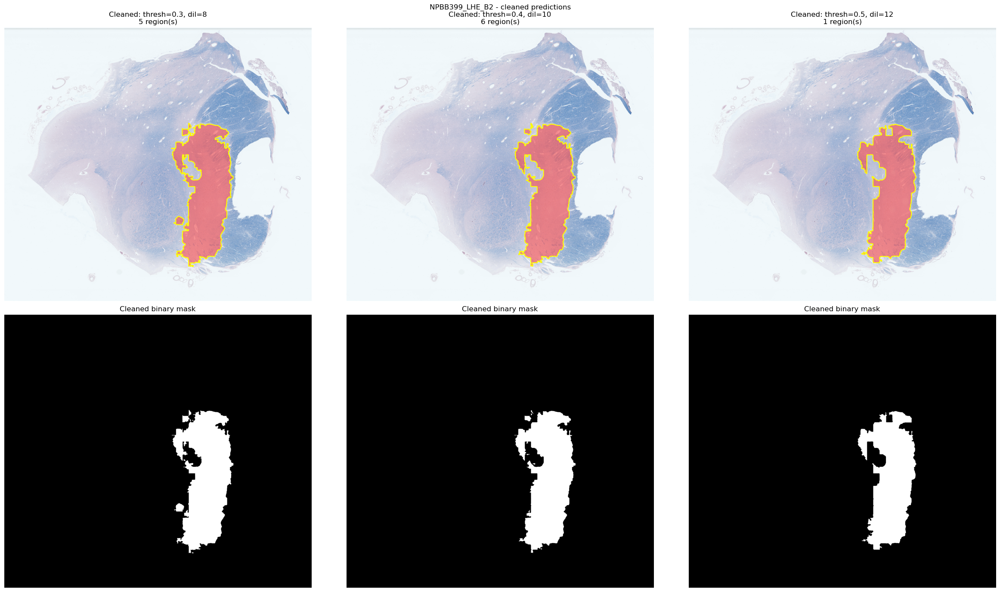


Predicting: NPBB13_LHE_B11
  Thumbnail: 6597 x 4650
  Prediction complete
  After threshold:   2,508,619 pixels
  After dilation:    2,670,306 pixels
  After erosion:     2,571,218 pixels
  Regions kept:      16
  Clusters found: 14 | kept: 1 | removed: 13
  Saved: NPBB13_LHE_B11_thresh0.3_dil8.geojson
  After threshold:   2,443,056 pixels
  After dilation:    2,631,245 pixels
  After erosion:     2,508,797 pixels
  Regions kept:      11
  Clusters found: 9 | kept: 1 | removed: 8
  Saved: NPBB13_LHE_B11_thresh0.4_dil10.geojson
  After threshold:   2,313,870 pixels
  After dilation:    2,493,695 pixels
  After erosion:     2,377,139 pixels
  Regions kept:      6
  Clusters found: 4 | kept: 1 | removed: 3
  Saved: NPBB13_LHE_B11_thresh0.5_dil12.geojson


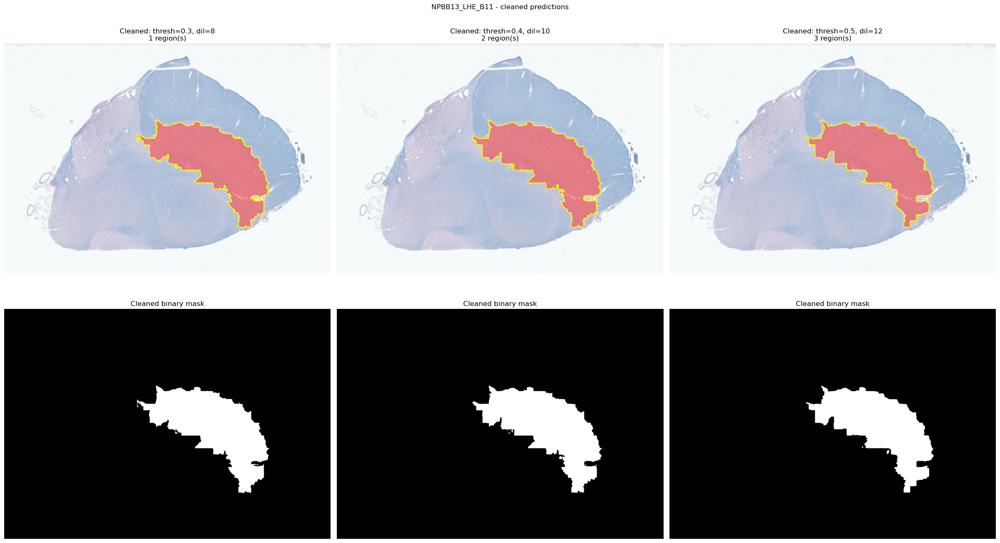


Predicting: NPBB15_HE_B11
  Thumbnail: 6421 x 5492
  Prediction complete
  After threshold:   2,990,160 pixels
  After dilation:    3,286,724 pixels
  After erosion:     3,115,721 pixels
  Regions kept:      33
  Clusters found: 19 | kept: 1 | removed: 18
  Saved: NPBB15_HE_B11_thresh0.3_dil8.geojson
  After threshold:   2,869,659 pixels
  After dilation:    3,206,677 pixels
  After erosion:     2,998,902 pixels
  Regions kept:      27
  Clusters found: 21 | kept: 1 | removed: 20
  Saved: NPBB15_HE_B11_thresh0.4_dil10.geojson
  After threshold:   2,628,378 pixels
  After dilation:    2,935,959 pixels
  After erosion:     2,740,585 pixels
  Regions kept:      24
  Clusters found: 15 | kept: 1 | removed: 14
  Saved: NPBB15_HE_B11_thresh0.5_dil12.geojson


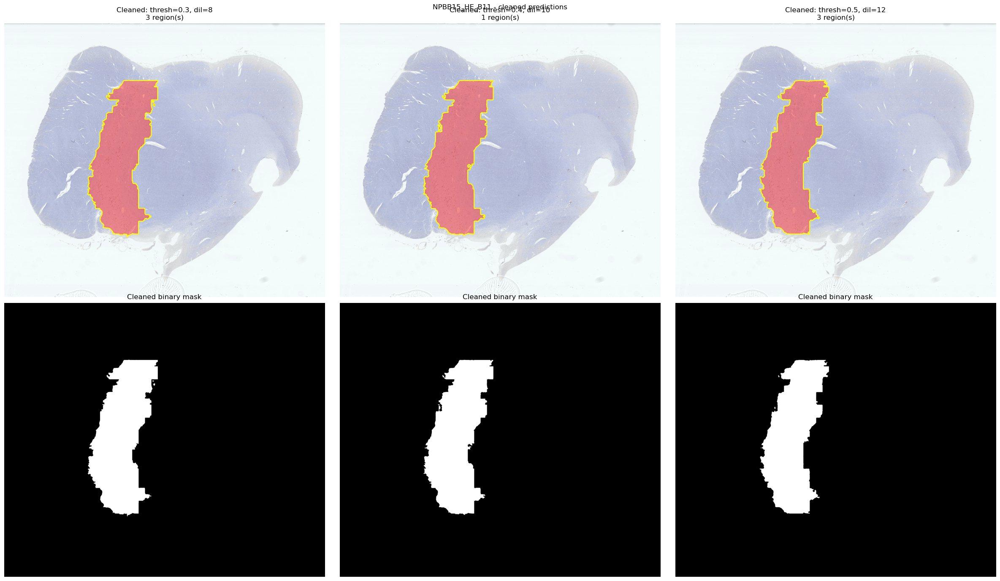


Predicting: NPBB390_LHE_B2
  Thumbnail: 7627 x 5052
  Prediction complete
  After threshold:   2,591,593 pixels
  After dilation:    2,918,124 pixels
  After erosion:     2,713,614 pixels
  Regions kept:      37
  Clusters found: 26 | kept: 1 | removed: 25
  Saved: NPBB390_LHE_B2_thresh0.3_dil8.geojson
  After threshold:   2,438,046 pixels
  After dilation:    2,823,711 pixels
  After erosion:     2,577,726 pixels
  Regions kept:      34
  Clusters found: 24 | kept: 1 | removed: 23
  Saved: NPBB390_LHE_B2_thresh0.4_dil10.geojson
  After threshold:   2,148,943 pixels
  After dilation:    2,473,876 pixels
  After erosion:     2,234,104 pixels
  Regions kept:      25
  Clusters found: 17 | kept: 1 | removed: 16
  Saved: NPBB390_LHE_B2_thresh0.5_dil12.geojson


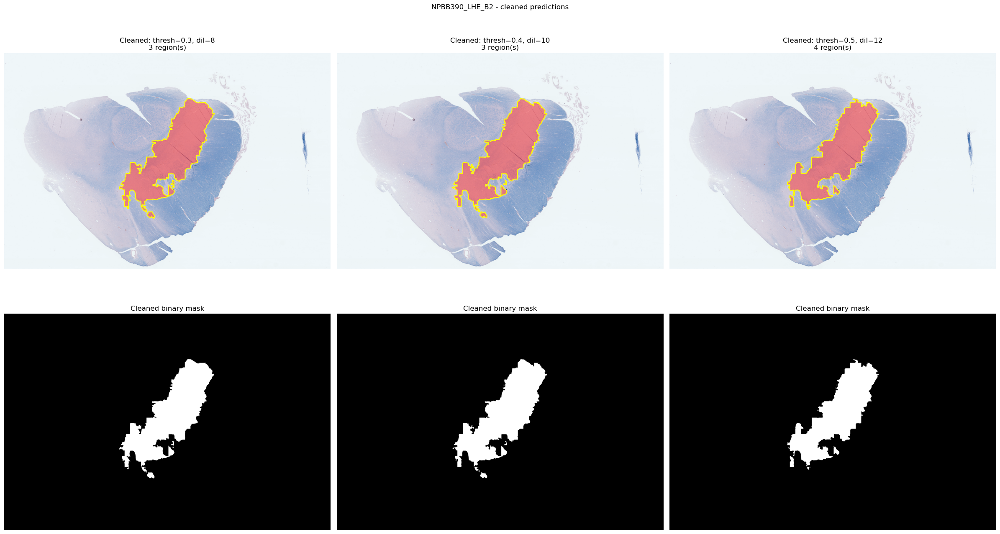


Predicting: NPBB25_LHE_B11
  Thumbnail: 6672 x 5215
  Prediction complete
  After threshold:   2,631,733 pixels
  After dilation:    2,857,958 pixels
  After erosion:     2,731,523 pixels
  Regions kept:      21
  Clusters found: 14 | kept: 1 | removed: 13
  Saved: NPBB25_LHE_B11_thresh0.3_dil8.geojson
  After threshold:   2,531,556 pixels
  After dilation:    2,804,683 pixels
  After erosion:     2,645,850 pixels
  Regions kept:      17
  Clusters found: 10 | kept: 1 | removed: 9
  Saved: NPBB25_LHE_B11_thresh0.4_dil10.geojson
  After threshold:   2,340,565 pixels
  After dilation:    2,609,286 pixels
  After erosion:     2,448,406 pixels
  Regions kept:      12
  Clusters found: 7 | kept: 1 | removed: 6
  Saved: NPBB25_LHE_B11_thresh0.5_dil12.geojson


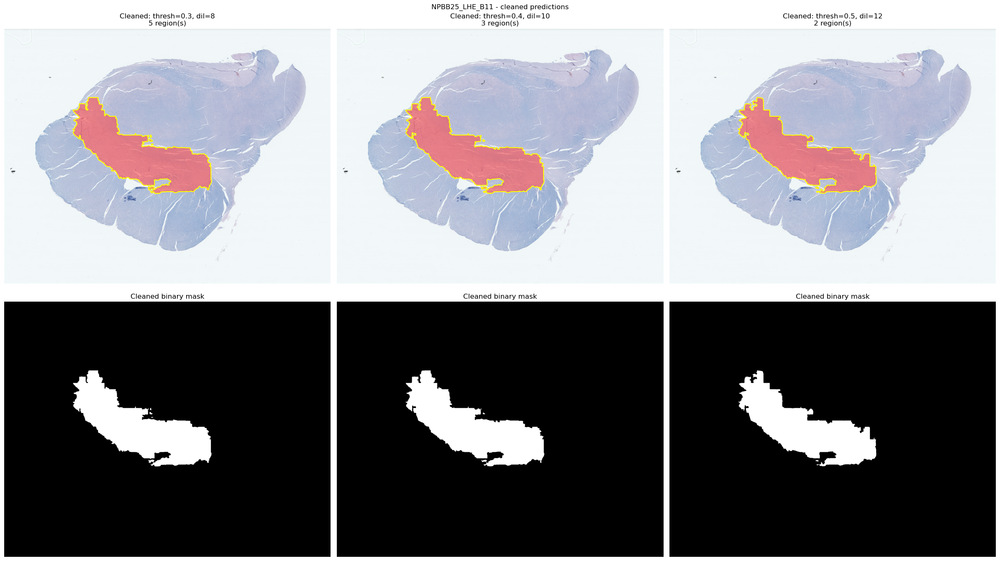


Predicting: NPBB398_LHE_B3
  Thumbnail: 7451 x 4637
  Prediction complete
  After threshold:   2,303,760 pixels
  After dilation:    2,541,650 pixels
  After erosion:     2,395,438 pixels
  Regions kept:      21
  Clusters found: 16 | kept: 1 | removed: 15
  Saved: NPBB398_LHE_B3_thresh0.3_dil8.geojson
  After threshold:   2,191,372 pixels
  After dilation:    2,478,691 pixels
  After erosion:     2,293,768 pixels
  Regions kept:      25
  Clusters found: 15 | kept: 1 | removed: 14
  Saved: NPBB398_LHE_B3_thresh0.4_dil10.geojson
  After threshold:   2,008,651 pixels
  After dilation:    2,271,869 pixels
  After erosion:     2,081,696 pixels
  Regions kept:      19
  Clusters found: 14 | kept: 1 | removed: 13
  Saved: NPBB398_LHE_B3_thresh0.5_dil12.geojson


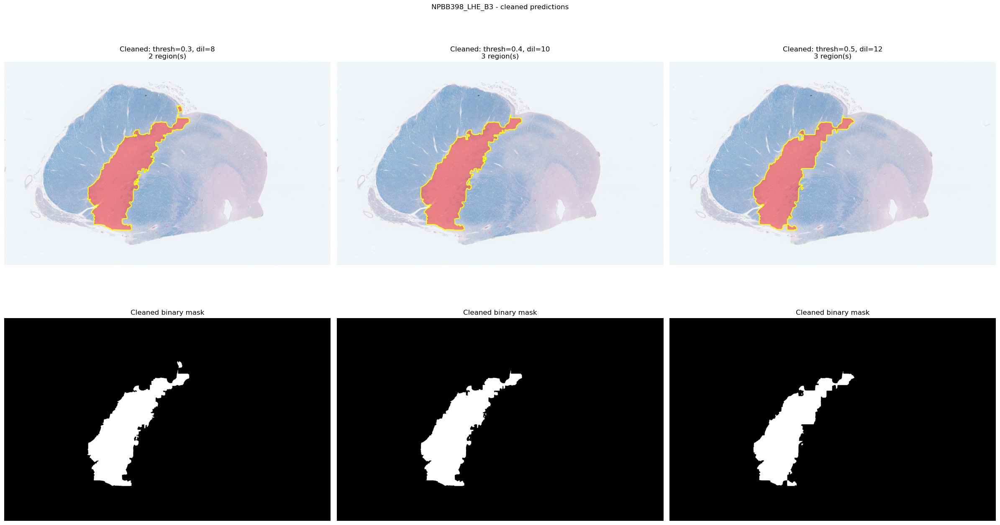


Predicting: NPPBB29_HE_B11
  Thumbnail: 6547 x 5014
  Prediction complete
  After threshold:   2,414,564 pixels
  After dilation:    2,669,187 pixels
  After erosion:     2,505,371 pixels
  Regions kept:      32
  Clusters found: 25 | kept: 1 | removed: 24
  Saved: NPPBB29_HE_B11_thresh0.3_dil8.geojson
  After threshold:   2,318,491 pixels
  After dilation:    2,605,802 pixels
  After erosion:     2,410,818 pixels
  Regions kept:      27
  Clusters found: 17 | kept: 1 | removed: 16
  Saved: NPPBB29_HE_B11_thresh0.4_dil10.geojson
  After threshold:   2,117,129 pixels
  After dilation:    2,372,049 pixels
  After erosion:     2,190,391 pixels
  Regions kept:      18
  Clusters found: 13 | kept: 1 | removed: 12
  Saved: NPPBB29_HE_B11_thresh0.5_dil12.geojson


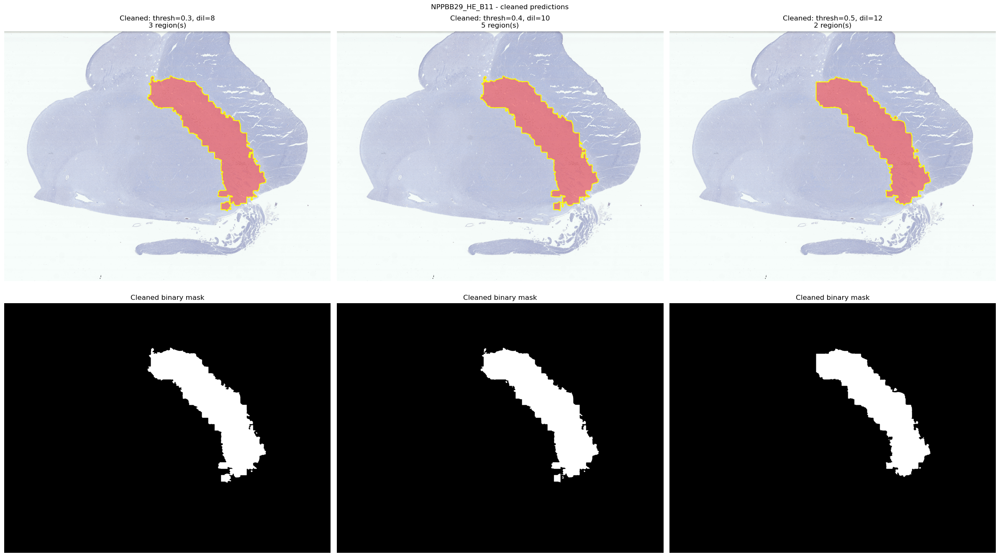


Predicting: NPBB14_HE_B11
  Thumbnail: 6961 x 5027
  Prediction complete
  After threshold:   2,748,394 pixels
  After dilation:    2,915,480 pixels
  After erosion:     2,820,200 pixels
  Regions kept:      21
  Clusters found: 14 | kept: 1 | removed: 13
  Saved: NPBB14_HE_B11_thresh0.3_dil8.geojson
  After threshold:   2,679,565 pixels
  After dilation:    2,869,747 pixels
  After erosion:     2,762,512 pixels
  Regions kept:      14
  Clusters found: 10 | kept: 1 | removed: 9
  Saved: NPBB14_HE_B11_thresh0.4_dil10.geojson
  After threshold:   2,553,685 pixels
  After dilation:    2,747,394 pixels
  After erosion:     2,639,659 pixels
  Regions kept:      6
  Clusters found: 4 | kept: 1 | removed: 3
  Saved: NPBB14_HE_B11_thresh0.5_dil12.geojson


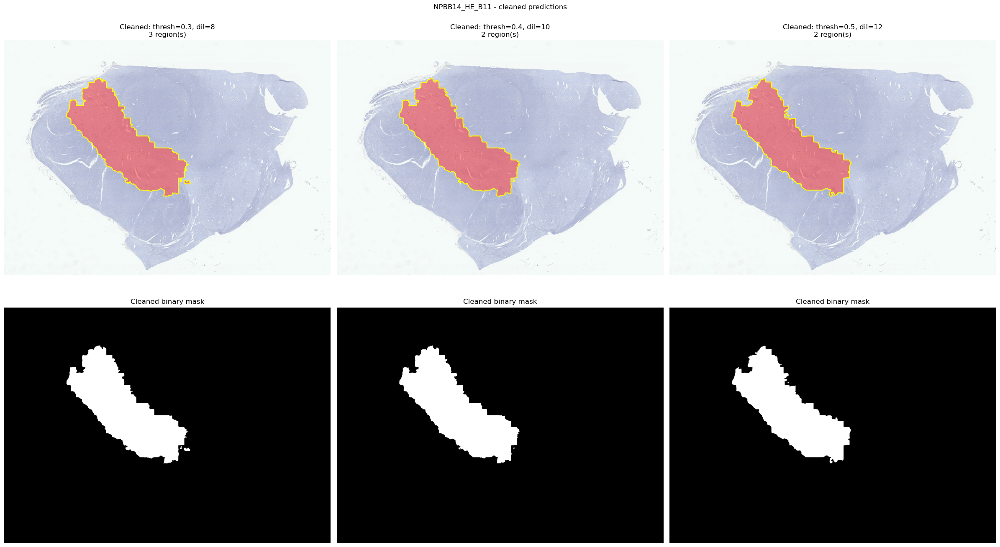


Predicting: NPBB23_HE_B11
  Thumbnail: 6785 x 4462
  Prediction complete
  After threshold:   2,367,075 pixels
  After dilation:    2,650,067 pixels
  After erosion:     2,518,261 pixels
  Regions kept:      24
  Clusters found: 16 | kept: 1 | removed: 15
  Saved: NPBB23_HE_B11_thresh0.3_dil8.geojson
  After threshold:   2,240,038 pixels
  After dilation:    2,580,209 pixels
  After erosion:     2,410,499 pixels
  Regions kept:      23
  Clusters found: 14 | kept: 1 | removed: 13
  Saved: NPBB23_HE_B11_thresh0.4_dil10.geojson
  After threshold:   1,962,184 pixels
  After dilation:    2,290,238 pixels
  After erosion:     2,147,971 pixels
  Regions kept:      11
  Clusters found: 7 | kept: 1 | removed: 6
  Saved: NPBB23_HE_B11_thresh0.5_dil12.geojson


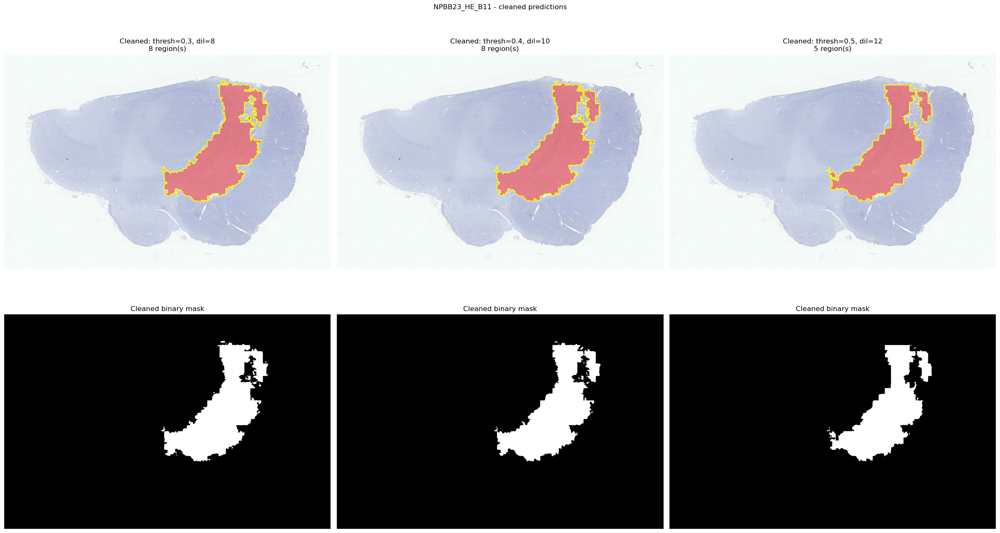


Predicting: NPB137_LHE_B10
  Thumbnail: 6019 x 5504
  Prediction complete
  After threshold:   1,951,075 pixels
  After dilation:    2,247,106 pixels
  After erosion:     2,078,041 pixels
  Regions kept:      41
  Clusters found: 28 | kept: 1 | removed: 27
  Saved: NPB137_LHE_B10_thresh0.3_dil8.geojson
  After threshold:   1,822,073 pixels
  After dilation:    2,171,318 pixels
  After erosion:     1,963,285 pixels
  Regions kept:      35
  Clusters found: 29 | kept: 1 | removed: 28
  Saved: NPB137_LHE_B10_thresh0.4_dil10.geojson
  After threshold:   1,557,295 pixels
  After dilation:    1,860,694 pixels
  After erosion:     1,677,910 pixels
  Regions kept:      19
  Clusters found: 15 | kept: 1 | removed: 14
  Saved: NPB137_LHE_B10_thresh0.5_dil12.geojson


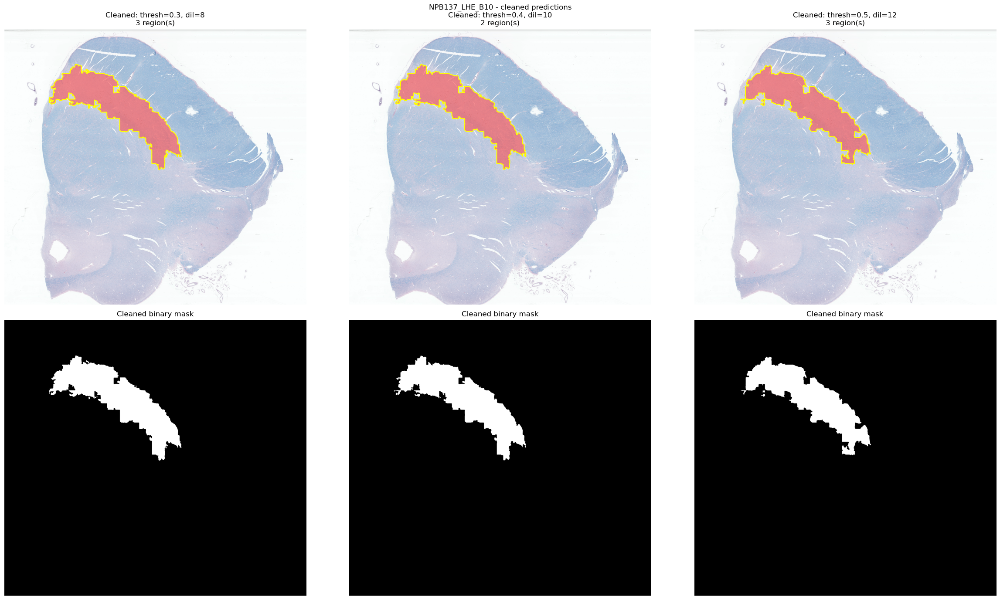


Predicting: NPBB202_LHE_B3
  Thumbnail: 7175 x 4838
  Prediction complete
  After threshold:   1,845,042 pixels
  After dilation:    1,992,862 pixels
  After erosion:     1,896,094 pixels
  Regions kept:      19
  Clusters found: 12 | kept: 1 | removed: 11
  Saved: NPBB202_LHE_B3_thresh0.3_dil8.geojson
  After threshold:   1,786,120 pixels
  After dilation:    1,960,729 pixels
  After erosion:     1,841,991 pixels
  Regions kept:      9
  Clusters found: 7 | kept: 1 | removed: 6
  Saved: NPBB202_LHE_B3_thresh0.4_dil10.geojson
  After threshold:   1,660,607 pixels
  After dilation:    1,832,415 pixels
  After erosion:     1,710,527 pixels
  Regions kept:      7
  Clusters found: 3 | kept: 1 | removed: 2
  Saved: NPBB202_LHE_B3_thresh0.5_dil12.geojson


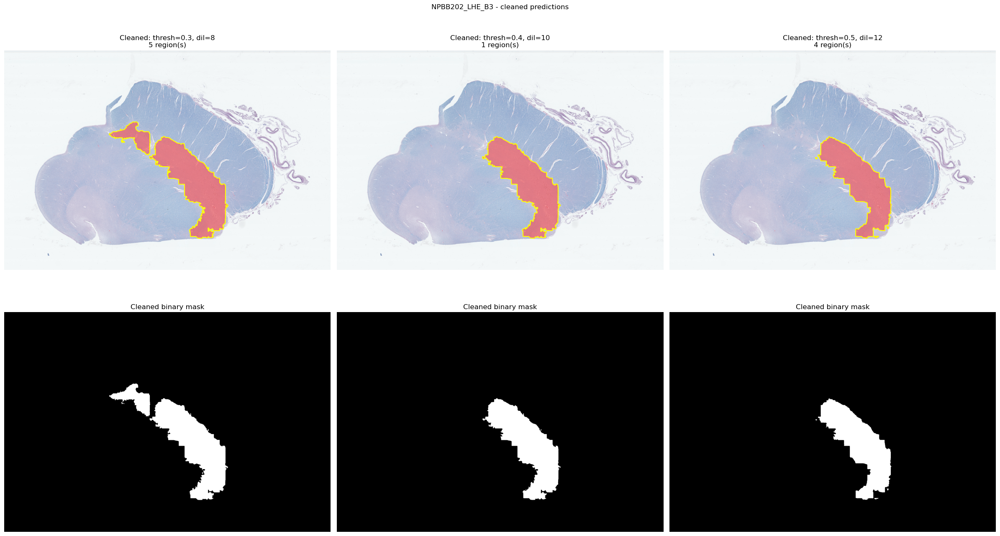

In [11]:
import glob
import json
import cv2
from skimage.measure import label, regionprops

# ── Cluster cleanup settings (tweak these) ───────────────
MERGE_RADIUS  = 25    # px: fragments closer than this count as ONE cluster
MIN_FRACTION  = 0.25  # keep clusters >= this fraction of the largest cluster's area
MAX_CLUSTERS  = None  # e.g. 1 = only the single biggest cluster, 2 = top two, None = no cap


def keep_main_clusters(mask, merge_radius=MERGE_RADIUS,
                       min_fraction=MIN_FRACTION, max_clusters=MAX_CLUSTERS):
    """
    Keep only the big cluster(s) of the mask and drop small/isolated pieces.
    1. Temporarily dilate so nearby fragments group into one cluster.
    2. Measure each cluster's area using the ORIGINAL mask pixels.
    3. Keep clusters that are big relative to the largest one.
    The returned mask uses original (undilated) pixels, so shapes don't grow.
    """
    mask = (mask > 0).astype(np.uint8)
    if mask.sum() == 0:
        return mask

    k = cv2.getStructuringElement(
        cv2.MORPH_ELLIPSE, (2 * merge_radius + 1, 2 * merge_radius + 1)
    )
    grouped = cv2.dilate(mask, k)
    labeled = label(grouped)

    areas = {}
    for prop in regionprops(labeled):
        areas[prop.label] = int(mask[labeled == prop.label].sum())

    ranked  = sorted(areas, key=areas.get, reverse=True)
    largest = areas[ranked[0]]
    keep    = [l for l in ranked if areas[l] >= min_fraction * largest]
    if max_clusters is not None:
        keep = keep[:max_clusters]

    print(f"  Clusters found: {len(ranked)} | kept: {len(keep)} | "
          f"removed: {len(ranked) - len(keep)}")

    out = np.zeros_like(mask)
    for l in keep:
        out[(labeled == l) & (mask > 0)] = 1
    return out


all_slides  = glob.glob(os.path.join(SLIDE_DIR, "*.svs")) + \
              glob.glob(os.path.join(SLIDE_DIR, "*.tif"))
unannotated = [s for s in all_slides
               if not any(t in os.path.basename(s) for t in TRAINING_SLIDES)]

print(f"Unannotated slides: {len(unannotated)}")
for s in unannotated:
    print(f"  {os.path.basename(s)}")

torch.cuda.empty_cache()

for slide_path in unannotated:
    slide_name = os.path.splitext(os.path.basename(slide_path))[0]
    print(f"\nPredicting: {slide_name}")

    try:
        prob_map, thumb = predict_on_slide(slide_path, model)

        oslide           = openslide.OpenSlide(slide_path)
        base_w, base_h   = oslide.dimensions
        thumb_h, thumb_w = thumb.shape[:2]
        scale_x          = base_w / thumb_w
        scale_y          = base_h / thumb_h
        oslide.close()

        # Post-processing comparison
        settings = [
            {"threshold": 0.3, "dilation": 8,  "min_size": 500},
            {"threshold": 0.4, "dilation": 10, "min_size": 500},
            {"threshold": 0.5, "dilation": 12, "min_size": 500},
        ]

        fig, axes = plt.subplots(2, 3, figsize=(24, 14))
        for i, s in enumerate(settings):
            clean = postprocess_prediction(
                prob_map,
                threshold=s["threshold"],
                dilation_radius=s["dilation"],
                min_region_size=s["min_size"]
            )
            clean = keep_main_clusters(clean)
            gj = mask_to_geojson(clean, scale_x, scale_y)

            # Postprocessed result: red fill + yellow outline on the slide
            overlay = thumb.copy()
            overlay[clean > 0] = (0.5 * overlay[clean > 0]
                                  + 0.5 * np.array([255, 50, 50])).astype(np.uint8)
            axes[0][i].imshow(overlay)
            for c in find_contours(clean.astype(float), 0.5):
                axes[0][i].plot(c[:, 1], c[:, 0], color="yellow", linewidth=1.5)
            axes[0][i].set_title(
                f"Cleaned: thresh={s['threshold']}, dil={s['dilation']}\n"
                f"{len(gj['features'])} region(s)"
            )
            axes[0][i].axis("off")
            axes[1][i].imshow(clean, cmap="gray")
            axes[1][i].set_title("Cleaned binary mask")
            axes[1][i].axis("off")

            out = os.path.join(PRED_DIR,
                f"{slide_name}_thresh{s['threshold']}_dil{s['dilation']}.geojson")
            with open(out, "w") as f:
                json.dump(gj, f)
            print(f"  Saved: {os.path.basename(out)}")

        plt.suptitle(f"{slide_name} - cleaned predictions")
        plt.tight_layout()
        plt.show()

    except Exception as e:
        import traceback
        print(f"  ERROR: {e}")
        traceback.print_exc()